In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error
)

In [2]:
df = pd.read_csv("../datasets/processed/cleaned_train.csv")

df.head()

,text,label,cleaned_text
0,hello this is the national lottery center cong...,1,hello this is the national lottery center cong...
1,i am a traffic consultation assistant i can he...,1,i am a traffic consultation assistant i can he...
2,sez hows u de arab boy hope u r all good give ...,0,sez hows u de arab boy hope u r all good give ...
3,i like to travel domestically or international...,0,i like to travel domestically or international...
4,welcome are there any products you would like ...,1,welcome are there any products you would like ...


In [3]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nLabel distribution:")
print(df["label"].value_counts())

Dataset shape: (30409, 3)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 30409 entries, 0 to 30408
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   text          30409 non-null  str  
 1   label         30409 non-null  int64
 2   cleaned_text  30409 non-null  str  
dtypes: int64(1), str(2)
memory usage: 712.8 KB

Label distribution:
label
1    19379
0    11030
Name: count, dtype: int64


In [4]:
X = df["cleaned_text"]
y = df["label"]

In [5]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (30409,)
y shape: (30409,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [7]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Training samples: 24327
Testing samples: 6082

Training label distribution:
label
1    15503
0     8824
Name: count, dtype: int64

Testing label distribution:
label
1    3876
0    2206
Name: count, dtype: int64


In [8]:
vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

In [9]:
X_train_tfidf = vectorizer.fit_transform(X_train)

X_test_tfidf = vectorizer.transform(X_test)

In [10]:
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (24327, 10000)
Testing TF-IDF shape: (6082, 10000)


In [11]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_tfidf, y_train)

lr_pred = lr_model.predict(X_test_tfidf)

In [12]:
print("Logistic Regression")
print("--------------------")

print("Accuracy:", accuracy_score(y_test, lr_pred))
print("Precision:", precision_score(y_test, lr_pred))
print("Recall:", recall_score(y_test, lr_pred))
print("F1 Score:", f1_score(y_test, lr_pred))

print("\nClassification Report:")
print(classification_report(y_test, lr_pred))

Logistic Regression
--------------------
Accuracy: 0.9886550476816837
Precision: 0.9945440374123149
Recall: 0.9876160990712074
F1 Score: 0.9910679611650486

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      2206
           1       0.99      0.99      0.99      3876

    accuracy                           0.99      6082
   macro avg       0.99      0.99      0.99      6082
weighted avg       0.99      0.99      0.99      6082



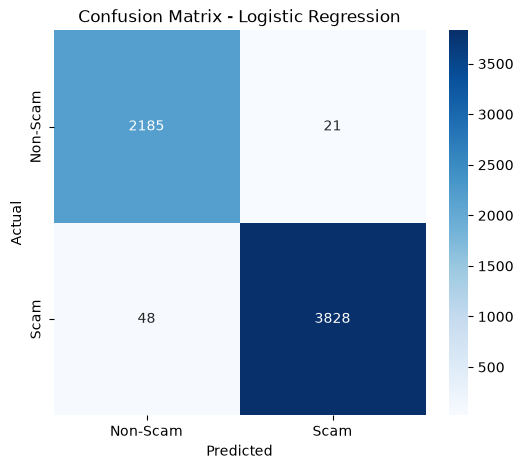

In [13]:
cm_lr = confusion_matrix(y_test, lr_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Scam", "Scam"],
    yticklabels=["Non-Scam", "Scam"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

In [14]:
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_pred = nb_model.predict(X_test_tfidf)

In [15]:
print("Naive Bayes")
print("-----------")

print("Accuracy:", accuracy_score(y_test, nb_pred))
print("Precision:", precision_score(y_test, nb_pred))
print("Recall:", recall_score(y_test, nb_pred))
print("F1 Score:", f1_score(y_test, nb_pred))

print("\nClassification Report:")
print(classification_report(y_test, nb_pred))

Naive Bayes
-----------
Accuracy: 0.9506741203551463
Precision: 0.9558898521162672
Recall: 0.967234262125903
F1 Score: 0.9615285970761733

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.92      0.93      2206
           1       0.96      0.97      0.96      3876

    accuracy                           0.95      6082
   macro avg       0.95      0.94      0.95      6082
weighted avg       0.95      0.95      0.95      6082



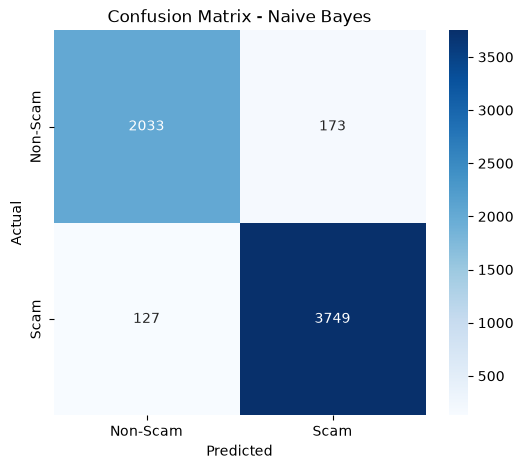

In [16]:
cm_nb = confusion_matrix(y_test, nb_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Scam", "Scam"],
    yticklabels=["Non-Scam", "Scam"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Naive Bayes")

plt.show()

In [17]:
svm_model = LinearSVC()

svm_model.fit(X_train_tfidf, y_train)

svm_pred = svm_model.predict(X_test_tfidf)

In [18]:
print("Linear SVM")
print("----------")

print("Accuracy:", accuracy_score(y_test, svm_pred))
print("Precision:", precision_score(y_test, svm_pred))
print("Recall:", recall_score(y_test, svm_pred))
print("F1 Score:", f1_score(y_test, svm_pred))

print("\nClassification Report:")
print(classification_report(y_test, svm_pred))

Linear SVM
----------
Accuracy: 0.9942453140414338
Precision: 0.9984427718660783
Recall: 0.9925180598555211
F1 Score: 0.9954716004657782

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      2206
           1       1.00      0.99      1.00      3876

    accuracy                           0.99      6082
   macro avg       0.99      0.99      0.99      6082
weighted avg       0.99      0.99      0.99      6082



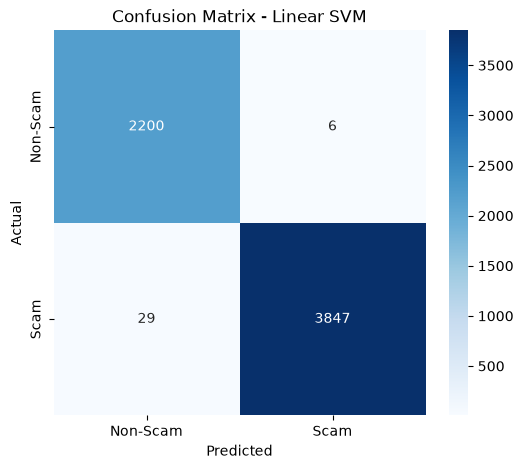

In [19]:
cm_svm = confusion_matrix(y_test, svm_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Scam", "Scam"],
    yticklabels=["Non-Scam", "Scam"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Linear SVM")

plt.show()

In [20]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Linear SVM"
    ],
    
    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, nb_pred),
        accuracy_score(y_test, svm_pred)
    ],
    
    "Precision": [
        precision_score(y_test, lr_pred),
        precision_score(y_test, nb_pred),
        precision_score(y_test, svm_pred)
    ],
    
    "Recall": [
        recall_score(y_test, lr_pred),
        recall_score(y_test, nb_pred),
        recall_score(y_test, svm_pred)
    ],
    
    "F1 Score": [
        f1_score(y_test, lr_pred),
        f1_score(y_test, nb_pred),
        f1_score(y_test, svm_pred)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.988655,0.994544,0.987616,0.991068
1,Naive Bayes,0.950674,0.955890,0.967234,0.961529
2,Linear SVM,0.994245,0.998443,0.992518,0.995472


In [21]:
comparison_rounded = comparison.copy()

comparison_rounded[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
] = comparison_rounded[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].round(4)

comparison_rounded

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9887,0.9945,0.9876,0.9911
1,Naive Bayes,0.9507,0.9559,0.9672,0.9615
2,Linear SVM,0.9942,0.9984,0.9925,0.9955


In [22]:
best_model = comparison.loc[
    comparison["F1 Score"].idxmax()
]

print("Best model based on F1 Score:")
print(best_model)

Best model based on F1 Score:
Model        Linear SVM
Accuracy       0.994245
Precision      0.998443
Recall         0.992518
F1 Score       0.995472
Name: 2, dtype: object


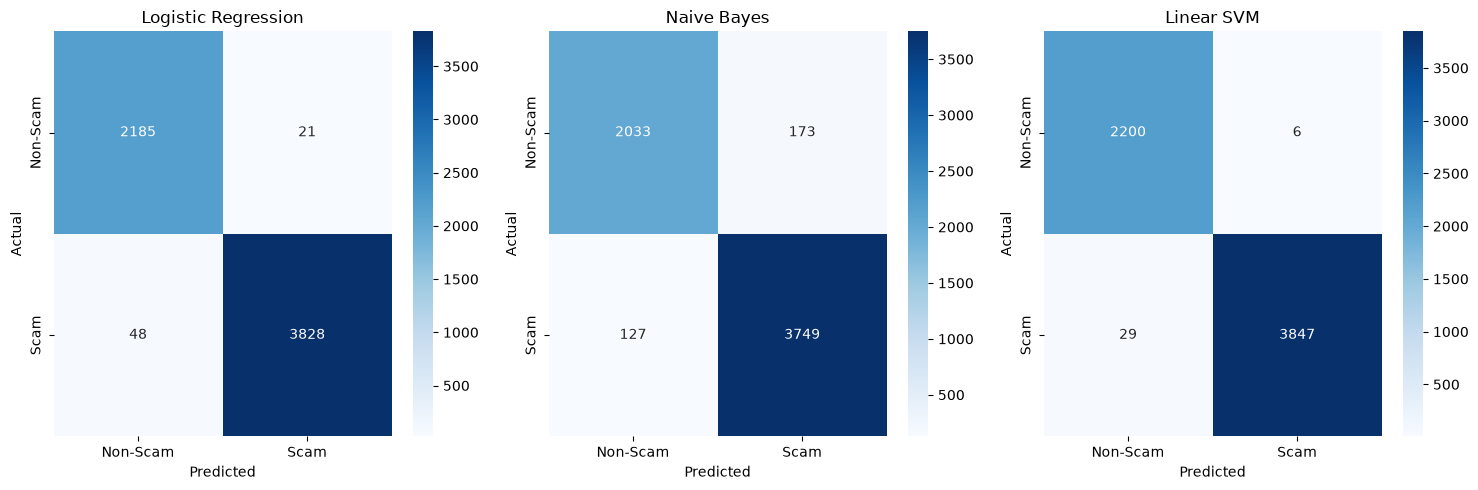

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

models = [
    ("Logistic Regression", lr_pred),
    ("Naive Bayes", nb_pred),
    ("Linear SVM", svm_pred)
]

for ax, (name, predictions) in zip(axes, models):

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-Scam", "Scam"],
        yticklabels=["Non-Scam", "Scam"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [24]:
from sklearn.linear_model import LinearRegression

reg_model = LinearRegression()

In [25]:
reg_model.fit(X_train_tfidf, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10000,)","[-0.01,-0.18,-0.06,..., 0.36,-0.03,-0.27]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.08809
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10000


In [26]:
reg_pred = reg_model.predict(X_test_tfidf)

print(reg_pred[:20])

[ 1.04646194  0.90318904  1.05507079  1.2188979   0.87139543 -0.04513297
  1.16753879  0.82794857  0.92453624  1.03905039  0.99643015  1.23817324
  1.00421862  0.23567733 -0.15533427 -0.0155461   1.09818819  0.96738692
  1.00456572  1.0481013 ]


In [27]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, reg_pred)

print("Mean Absolute Error:", mae)

Mean Absolute Error: 0.11560257117199857


In [28]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, reg_pred)

print("Mean Squared Error:", mse)

Mean Squared Error: 0.026760496129220702


In [29]:
import numpy as np

rmse = np.sqrt(mse)

print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 0.1635863567942654


In [30]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, reg_pred)
mse = mean_squared_error(y_test, reg_pred)
rmse = np.sqrt(mse)

print("Root Mean Squared Error:", rmse)
print("Mean Squared Error:", mse)
print("Mean Absolute Error:", mae)

Root Mean Squared Error: 0.1635863567942654
Mean Squared Error: 0.026760496129220702
Mean Absolute Error: 0.11560257117199857


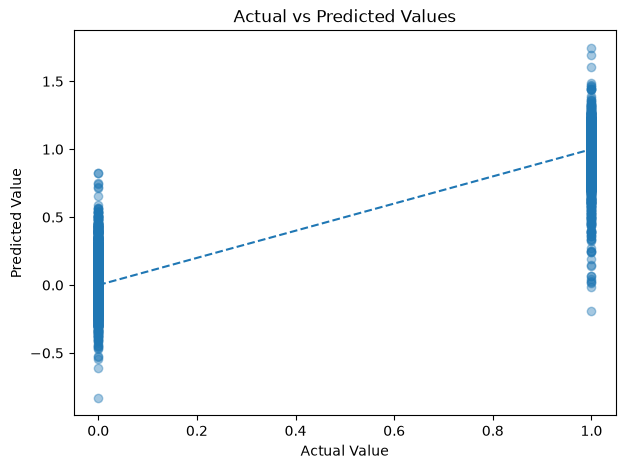

In [31]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, reg_pred, alpha=0.4)

# Ideal prediction line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("Actual Value")
plt.ylabel("Predicted Value")
plt.title("Actual vs Predicted Values")

plt.show()

In [32]:
regression_results = pd.DataFrame({
    "Metric": ["Mean Absolute Error (MAE)",
               "Mean Squared Error (MSE)",
               "Root Mean Squared Error (RMSE)"],
    "Linear Regression": [
        mae,
        mse,
        rmse
    ]
})

regression_results.round(4)

,Metric,Linear Regression
0,Mean Absolute Error (MAE),0.1156
1,Mean Squared Error (MSE),0.0268
2,Root Mean Squared Error (RMSE),0.1636


In [33]:
from sklearn.linear_model import Ridge, Lasso

In [34]:
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_tfidf, y_train)

ridge_pred = ridge_model.predict(X_test_tfidf)

print("First 20 Ridge predictions:")
print(ridge_pred[:20])

First 20 Ridge predictions:
[ 1.02740143  1.00374813  0.85776027  1.19306948  0.90188491  0.00972684
  1.09160066  0.77780474  0.86256051  0.93059837  1.04536165  1.07481617
  0.92061192 -0.07563666 -0.05398736 -0.00912015  1.09343427  0.94307561
  0.99883613  0.955808  ]


In [35]:
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)

print("Ridge Regression")
print("MAE:", ridge_mae)
print("MSE:", ridge_mse)
print("RMSE:", ridge_rmse)

Ridge Regression
MAE: 0.08789628828128436
MSE: 0.016788668767583934
RMSE: 0.12957109541708728


In [36]:
lasso_model = Lasso(alpha=0.001)

lasso_model.fit(X_train_tfidf, y_train)

lasso_pred = lasso_model.predict(X_test_tfidf)

print("First 20 Lasso predictions:")
print(lasso_pred[:20])

First 20 Lasso predictions:
[ 0.99576712  1.08691113  0.65932769  0.64536952  0.65339578  0.17196131
  1.01228564  0.82802071  0.73487713  0.5168949   1.11813581  0.96868745
  0.7647969  -0.10396298  0.35324954  0.26501713  0.63614626  0.51931399
  0.85138332  0.97186599]


In [37]:
lasso_mae = mean_absolute_error(y_test, lasso_pred)
lasso_mse = mean_squared_error(y_test, lasso_pred)
lasso_rmse = np.sqrt(lasso_mse)

print("Lasso Regression")
print("MAE:", lasso_mae)
print("MSE:", lasso_mse)
print("RMSE:", lasso_rmse)

Lasso Regression
MAE: 0.2260805122389699
MSE: 0.07913291630219522
RMSE: 0.28130573457040514


In [ ]:
regression_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],
    "MAE": [
        mae,
        ridge_mae,
        lasso_mae
    ],
    "MSE": [
        mse,
        ridge_mse,
        lasso_mse
    ],
    "RMSE": [
        rmse,
        ridge_rmse,
        lasso_rmse
    ]
})

regression_comparison.round(4)

,Model,MAE,MSE,RMSE
0,Linear Regression,0.1156,0.0268,0.1636
1,Ridge Regression,0.0879,0.0168,0.1296
2,Lasso Regression,0.2261,0.0791,0.2813


In [39]:
best_regression = regression_comparison.loc[
    regression_comparison["RMSE"].idxmin()
]

print("Best Regression Model:")
print(best_regression)

Best Regression Model:
Model    Ridge Regression
MAE              0.087896
MSE              0.016789
RMSE             0.129571
Name: 1, dtype: object


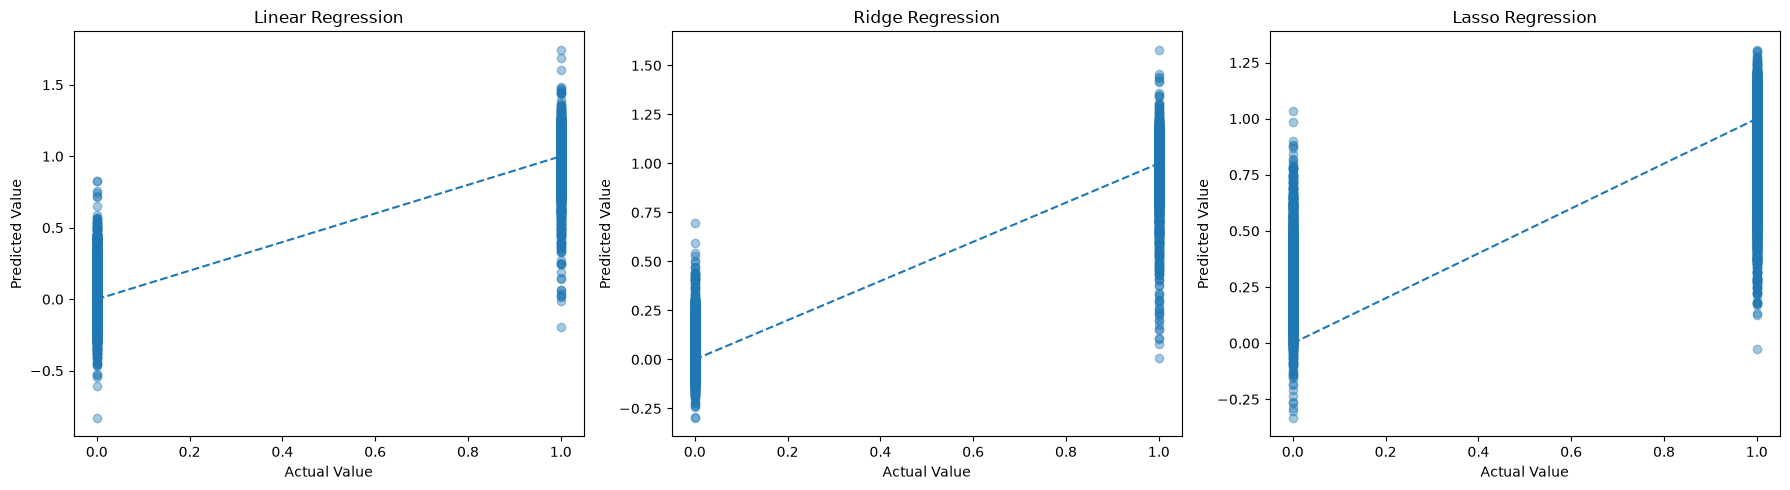

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models = [
    ("Linear Regression", reg_pred),
    ("Ridge Regression", ridge_pred),
    ("Lasso Regression", lasso_pred)
]

for ax, (name, predictions) in zip(axes, models):

    ax.scatter(y_test, predictions, alpha=0.4)

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    ax.set_title(name)
    ax.set_xlabel("Actual Value")
    ax.set_ylabel("Predicted Value")

plt.tight_layout()
plt.show()

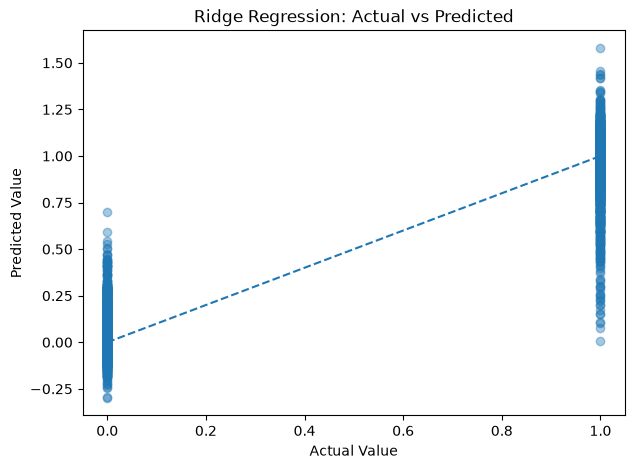

In [41]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, ridge_pred, alpha=0.4)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("Actual Value")
plt.ylabel("Predicted Value")
plt.title("Ridge Regression: Actual vs Predicted")

plt.show()

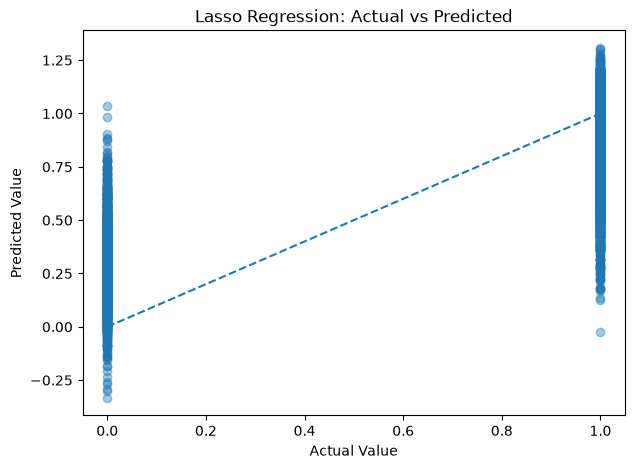

In [42]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, lasso_pred, alpha=0.4)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("Actual Value")
plt.ylabel("Predicted Value")
plt.title("Lasso Regression: Actual vs Predicted")

plt.show()